# Survival Analysis: พนักงานจะลาออกเมื่อไหร่ (Yanisa, wk6–7)

โมเดลหลักของทีม (XGBoost) ตอบว่า **"คนนี้เสี่ยงลาออกแค่ไหน"** โน้ตบุ๊กนี้ตอบอีกคำถามที่ HR อยากรู้คือ **"ถ้าจะลาออก มักลาออกตอนอยู่บริษัทมาได้กี่ปี และกลุ่มไหนลาออกเร็วกว่ากัน"** ด้วย Survival Analysis (การวิเคราะห์ระยะเวลาจนเกิดเหตุการณ์)

งานนี้อยู่ใน [TASKS.md](../TASKS.md) wk6–7 (Yanisa + Nanthamon) และเกี่ยวกับ DS-01 ใน [review Data Engineering](../docs/review_data_engineering_S.md)

### ศัพท์ที่ใช้ (ภาษาคน)
| ศัพท์ | ความหมายในงานนี้ |
| :--- | :--- |
| duration (ระยะเวลา) | `YearsAtCompany` = อยู่บริษัทมากี่ปี |
| event (เหตุการณ์) | ลาออก (`Attrition = Yes`) |
| censored (ข้อมูลยังไม่จบ) | คนที่ยังไม่ลาออก เรารู้แค่ว่า "อยู่มาแล้วอย่างน้อย X ปี" ไม่รู้ว่าจะออกเมื่อไหร่ |
| survival S(t) | สัดส่วนพนักงานที่ยัง**ไม่**ลาออกเมื่ออยู่มาครบ t ปี |
| hazard ratio (HR) | เทียบว่ากลุ่มหนึ่งมีโอกาสลาออกในแต่ละช่วงเวลามากกว่าอีกกลุ่มกี่เท่า HR = 2 คือ 2 เท่า, HR = 0.5 คือครึ่งเดียว |

ทำไมไม่ใช้ค่าเฉลี่ยอายุงานของคนที่ลาออกเฉยๆ: คนที่ยังไม่ลาออก (84% ของข้อมูล) ก็ให้ข้อมูลว่า "อยู่มาได้อย่างน้อยเท่านี้" ถ้าตัดทิ้งจะประเมินว่าคนลาออกเร็วเกินจริง Survival Analysis ใช้ข้อมูลทั้งสองกลุ่มอย่างถูกวิธี

### ข้อจำกัดที่ต้องรู้ก่อนอ่านผล (DS-01)
IBM dataset เป็นภาพถ่ายครั้งเดียว ไม่มีวันที่ ค่า `YearsAtCompany` ของคนลาออกคือ ณ วันที่ออก ส่วนคนที่ยังอยู่คือ ณ วันเก็บข้อมูล ซึ่งตรงกับรูปแบบ time-to-event + censoring พอดี แต่ค่าอื่น เช่น เงินเดือน ความพึงพอใจ เป็นค่า ณ ตอนนั้น ไม่ใช่ค่าตอนเริ่มงาน ผล Cox model จึงเป็น "ความสัมพันธ์" ไม่ใช่ "เหตุและผล"

ใช้ **statsmodels** (Kaplan-Meier, log-rank, Cox) แทน lifelines เพราะ lifelines ยังไม่รองรับ pandas 3 ที่โปรเจกต์ใช้

---
## ขั้นตอนที่ 1: เตรียมข้อมูล

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.duration.hazard_regression import PHReg
from statsmodels.duration.survfunc import SurvfuncRight, survdiff

sys.path.append(os.path.abspath(".."))
from src.clean_pipeline import RAW_FILENAME, load_raw_data

RAW_PATH = os.path.join("..", "data", "raw", RAW_FILENAME)
FIG_DIR = os.path.join("..", "docs", "figures", "survival_Y")
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")


def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")


df = load_raw_data(RAW_PATH)
df["duration"] = df["YearsAtCompany"]
df["event"] = (df["Attrition"] == "Yes").astype(int)
print(f"พนักงาน {len(df):,} คน: ลาออก (event) {df['event'].sum()} คน, ยังอยู่ (censored) {(df['event'] == 0).sum()} คน")
print(f"อยู่ไม่ถึง 1 ปี (YearsAtCompany = 0): {(df['duration'] == 0).sum()} คน, นานสุด {df['duration'].max()} ปี")

พนักงาน 1,470 คน: ลาออก (event) 237 คน, ยังอยู่ (censored) 1233 คน
อยู่ไม่ถึง 1 ปี (YearsAtCompany = 0): 44 คน, นานสุด 40 ปี


---
## ขั้นตอนที่ 2: Kaplan-Meier ภาพรวมทั้งบริษัท

เส้น Kaplan-Meier (KM) คือ "ถ้ารับคนเข้ามา 100 คน ผ่านไป t ปีจะเหลือกี่คน" แถบสีจางคือช่วงความเชื่อมั่น 95% (ยิ่งกว้างยิ่งไม่แน่นอน ช่วงปีหลังๆ คนเหลือน้อยแถบจึงกว้าง)

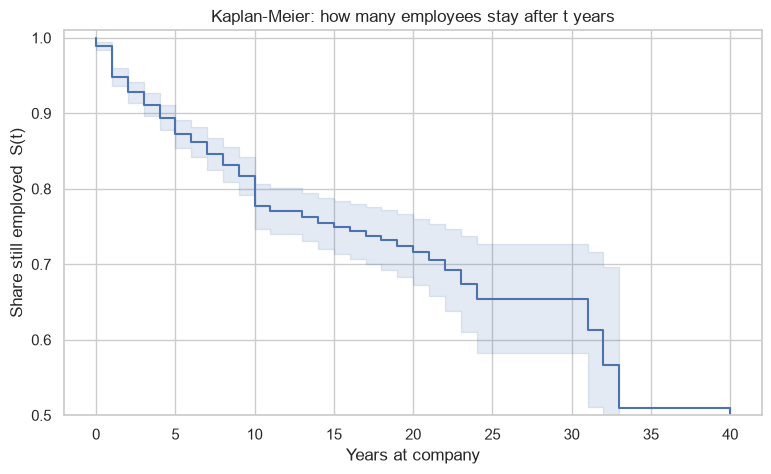

ปีที่อยู่บริษัท,ยังไม่ลาออก S(t)
1,94.8%
2,92.8%
3,91.1%
5,87.3%
10,77.7%
20,71.7%


In [2]:
def fmt_p(p):
    """p ที่เล็กกว่าความละเอียดของเครื่องจะออกมาเป็น 0 แสดงเป็น < 1e-16 แทน"""
    return "< 1e-16" if p < 1e-16 else f"{p:.1e}"


def surv_at(sf, t):
    """ค่า S(t) จากเส้น KM (เป็นขั้นบันได ใช้ค่าล่าสุดที่เวลา <= t)"""
    idx = np.searchsorted(sf.surv_times, t, side="right") - 1
    return 1.0 if idx < 0 else sf.surv_prob[idx]


def plot_km(ax, sf, label, color=None):
    times = np.r_[0, sf.surv_times]
    prob = np.r_[1, sf.surv_prob]
    ax.step(times, prob, where="post", label=label, color=color)
    # ช่วงความเชื่อมั่น 95% แบบรายจุด
    lo = np.clip(sf.surv_prob - 1.96 * sf.surv_prob_se, 0, 1)
    hi = np.clip(sf.surv_prob + 1.96 * sf.surv_prob_se, 0, 1)
    ax.fill_between(sf.surv_times, lo, hi, step="post", alpha=0.15, color=ax.lines[-1].get_color())


sf_all = SurvfuncRight(df["duration"], df["event"])
fig, ax = plt.subplots(figsize=(9, 5))
plot_km(ax, sf_all, "All employees")
ax.set_xlabel("Years at company")
ax.set_ylabel("Share still employed  S(t)")
ax.set_ylim(0.5, 1.01)
ax.set_title("Kaplan-Meier: how many employees stay after t years")
save(fig, "01_km_overall")
plt.show()

pd.DataFrame({"ปีที่อยู่บริษัท": [1, 2, 3, 5, 10, 20],
              "ยังไม่ลาออก S(t)": [surv_at(sf_all, t) for t in [1, 2, 3, 5, 10, 20]]}).style.format({"ยังไม่ลาออก S(t)": "{:.1%}"}).hide(axis="index")

---
## ขั้นตอนที่ 3: ปีไหนเสี่ยงที่สุด (อัตราลาออกรายปี)

ตอบตรงๆ ว่า "จะลาออกเมื่อไหร่": ในคนที่ยังอยู่ถึงปีที่ t มีกี่ % ลาออกในปีนั้น (เรียกว่า hazard รายปี) คำนวณจาก จำนวนคนที่ลาออกตอนอายุงาน t ÷ จำนวนคนที่อยู่มาถึง t ปี

ปีที่ 0 คือคนที่อยู่ไม่ถึง 1 ปี แสดงถึงปีที่ 15 เพราะหลังจากนั้นเหลือคนน้อย ตัวเลขแกว่งมาก

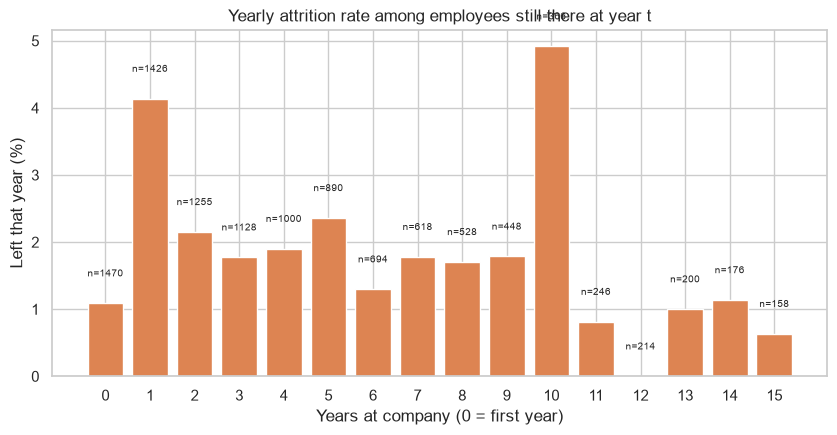

ในคนที่ลาออก 43% ลาออกภายใน 2 ปีแรก (YearsAtCompany 0–2)


year,at_risk,left,hazard
0,1470,16,1.1%
1,1426,59,4.1%
2,1255,27,2.2%
3,1128,20,1.8%
4,1000,19,1.9%
5,890,21,2.4%
6,694,9,1.3%
7,618,11,1.8%
8,528,9,1.7%
9,448,8,1.8%


In [3]:
life = pd.DataFrame({"year": range(0, 16)})
life["at_risk"] = [(df["duration"] >= t).sum() for t in life["year"]]
life["left"] = [((df["duration"] == t) & (df["event"] == 1)).sum() for t in life["year"]]
life["hazard"] = life["left"] / life["at_risk"]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(life["year"], life["hazard"] * 100, color="#DD8452")
for x, h, n in zip(life["year"], life["hazard"], life["at_risk"]):
    ax.text(x, h * 100 + 0.4, f"n={n}", ha="center", fontsize=7)
ax.set_xlabel("Years at company (0 = first year)")
ax.set_ylabel("Left that year (%)")
ax.set_xticks(life["year"])
ax.set_title("Yearly attrition rate among employees still there at year t")
save(fig, "02_hazard_by_year")
plt.show()

first2 = df.loc[df["event"] == 1, "duration"].le(2).mean()
print(f"ในคนที่ลาออก {first2:.0%} ลาออกภายใน 2 ปีแรก (YearsAtCompany 0–2)")
life.style.format({"hazard": "{:.1%}"}).hide(axis="index")

---
## ขั้นตอนที่ 4: เทียบเส้น KM ระหว่างกลุ่ม + log-rank test

เลือกกลุ่มที่ EDA (ทั้งฝั่งตัวเลขและหมวดหมู่) พบว่าต่างกันชัด แล้วดูว่า "ลาออกเร็วกว่า" กันจริงไหม

- **log-rank test** ทดสอบว่าเส้น KM ของทุกกลุ่มต่างกันจริงหรือเป็นความบังเอิญ `p < 0.05` = ต่างกันจริง
- ตารางด้านล่างกราฟแสดง S(2) และ S(5) = สัดส่วนที่ยังอยู่เมื่อครบ 2 และ 5 ปี

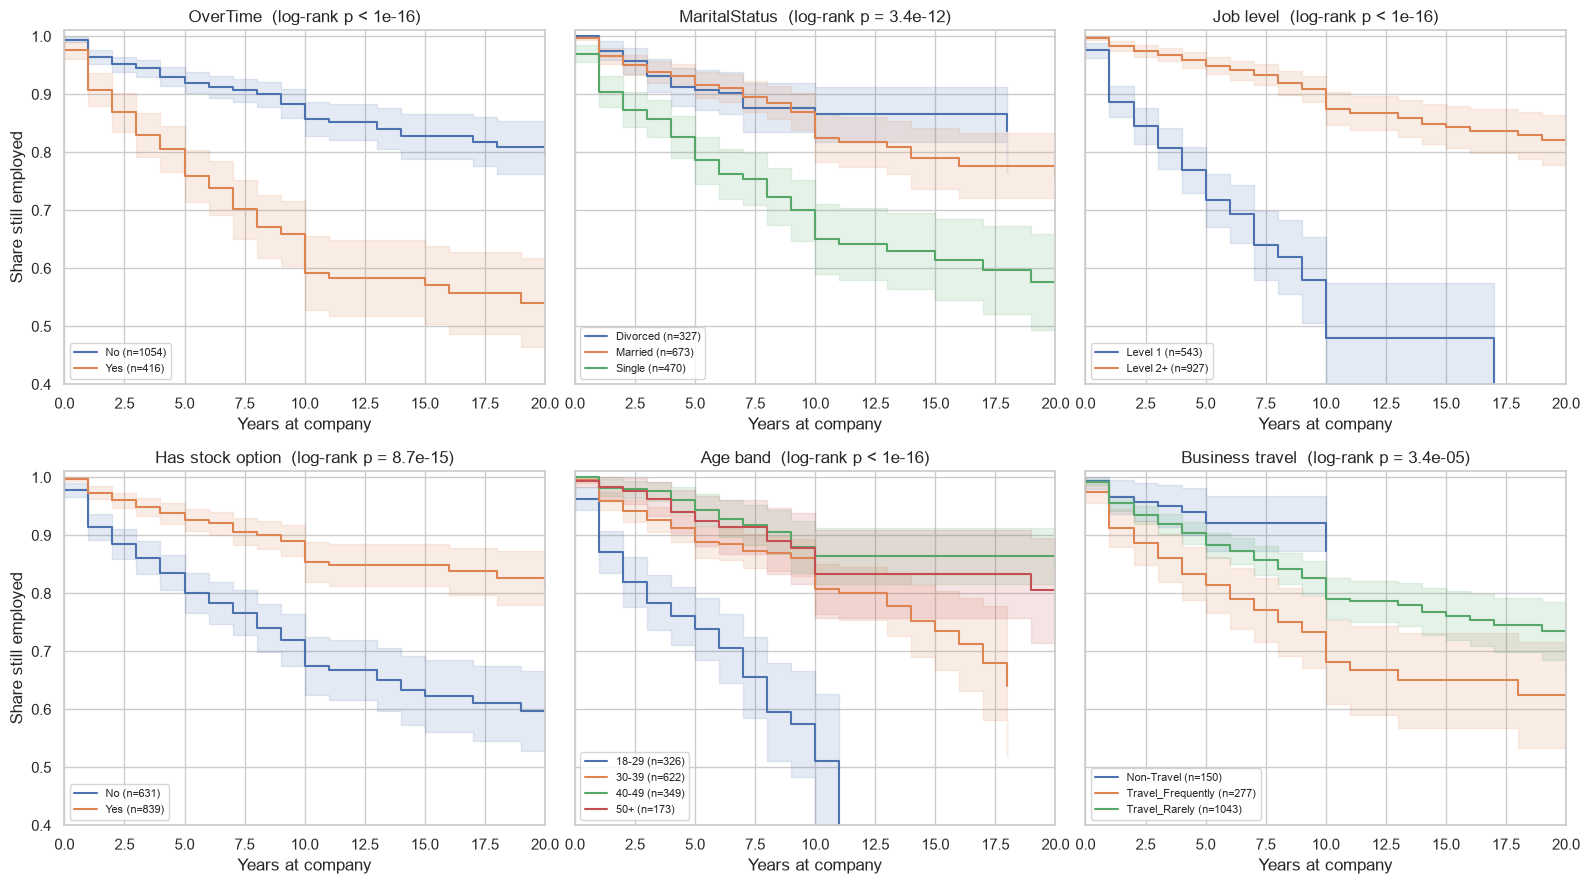

กลุ่ม,ค่า,คน,ลาออก,S(2),S(5),log-rank p
OverTime,No,1054,110,95.1%,92.0%,< 1e-16
OverTime,Yes,416,127,86.9%,75.9%,< 1e-16
MaritalStatus,Divorced,327,33,95.8%,90.8%,3.4e-12
MaritalStatus,Married,673,84,95.1%,91.6%,3.4e-12
MaritalStatus,Single,470,120,87.4%,78.6%,3.4e-12
JobLevelGroup,Level 1,543,143,84.6%,71.7%,< 1e-16
JobLevelGroup,Level 2+,927,94,97.4%,94.9%,< 1e-16
HasStockOption,No,631,154,88.4%,80.1%,8.7e-15
HasStockOption,Yes,839,83,96.0%,92.7%,8.7e-15
AgeBand,18-29,326,91,81.9%,73.8%,< 1e-16


In [4]:
df["AgeBand"] = pd.cut(df["Age"], [18, 30, 40, 50, 61], right=False, labels=["18-29", "30-39", "40-49", "50+"])
df["HasStockOption"] = np.where(df["StockOptionLevel"] > 0, "Yes", "No")
df["JobLevelGroup"] = np.where(df["JobLevel"] == 1, "Level 1", "Level 2+")

GROUPS = {
    "OverTime": "OverTime",
    "MaritalStatus": "MaritalStatus",
    "JobLevelGroup": "Job level",
    "HasStockOption": "Has stock option",
    "AgeBand": "Age band",
    "BusinessTravel": "Business travel",
}

rows = []
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
for ax, (col, title) in zip(axes.flat, GROUPS.items()):
    for level in sorted(df[col].dropna().unique()):
        part = df[df[col] == level]
        sf = SurvfuncRight(part["duration"], part["event"])
        plot_km(ax, sf, f"{level} (n={len(part)})")
        rows.append({"กลุ่ม": col, "ค่า": level, "คน": len(part), "ลาออก": part["event"].sum(),
                     "S(2)": surv_at(sf, 2), "S(5)": surv_at(sf, 5)})
    chisq, p = survdiff(df["duration"], df["event"], df[col].astype(str))
    ax.set_title(f"{title}  (log-rank p {fmt_p(p) if p < 1e-16 else '= ' + fmt_p(p)})")
    ax.set_xlim(0, 20)
    ax.set_ylim(0.4, 1.01)
    ax.set_xlabel("Years at company")
    ax.legend(fontsize=8, loc="lower left")
    for r in rows:
        if r["กลุ่ม"] == col:
            r["log-rank p"] = p
axes[0, 0].set_ylabel("Share still employed")
axes[1, 0].set_ylabel("Share still employed")
fig.tight_layout()
save(fig, "03_km_by_group")
plt.show()

pd.DataFrame(rows).style.format({"S(2)": "{:.1%}", "S(5)": "{:.1%}", "log-rank p": fmt_p}).hide(axis="index")

---
## ขั้นตอนที่ 5: Cox Proportional Hazards (ดูหลายปัจจัยพร้อมกัน)

KM เทียบได้ทีละปัจจัย แต่ปัจจัยหลายตัวเกี่ยวกัน (เช่น คนอายุน้อยมักเงินเดือนน้อยด้วย) Cox model ดูทุกปัจจัยพร้อมกัน แล้วบอกว่า**แต่ละปัจจัยมีผลเท่าไหร่เมื่อปัจจัยอื่นเท่ากัน** ผลออกมาเป็น hazard ratio (HR)

**ไม่ใส่** คอลัมน์ที่คำนวณมาจากเวลาที่อยู่บริษัท (`YearsInCurrentRole`, `YearsWithCurrManager`, `YearsSinceLastPromotion`, `TotalWorkingYears`) เพราะค่าพวกนี้โตขึ้นตามอายุงานเอง ถ้าใส่จะเหมือนเอาคำตอบ (duration) ไปทายตัวเอง และ `JobLevel` สัมพันธ์กับเงินเดือนสูงมาก (0.92 จาก EDA) จึงใส่แค่เงินเดือน

หน่วยของแต่ละปัจจัยตั้งให้อ่านง่าย เช่น เงินเดือนต่อ 1,000, ระยะทางต่อ 5 กม., ความพึงพอใจต่อ 1 ระดับ

In [5]:
cox = pd.DataFrame({
    "OverTime (yes)": (df["OverTime"] == "Yes").astype(int),
    "Monthly income (per 1,000)": df["MonthlyIncome"] / 1000,
    "Has stock option": (df["StockOptionLevel"] > 0).astype(int),
    "Age (per 5 years)": df["Age"] / 5,
    "Distance from home (per 5)": df["DistanceFromHome"] / 5,
    "Environment satisfaction (+1 level)": df["EnvironmentSatisfaction"],
    "Job satisfaction (+1 level)": df["JobSatisfaction"],
    "Job involvement (+1 level)": df["JobInvolvement"],
    "Work-life balance (+1 level)": df["WorkLifeBalance"],
    "Travel frequently": (df["BusinessTravel"] == "Travel_Frequently").astype(int),
    "Single": (df["MaritalStatus"] == "Single").astype(int),
    "Companies worked before": df["NumCompaniesWorked"],
})

cox_res = PHReg(df["duration"], cox, status=df["event"], ties="efron").fit()
ci = cox_res.conf_int()
hr = pd.DataFrame({
    "HR": np.exp(cox_res.params),
    "HR 95% CI ต่ำ": np.exp(ci[:, 0]),
    "HR 95% CI สูง": np.exp(ci[:, 1]),
    "p_value": cox_res.pvalues,
}, index=cox.columns).sort_values("HR")
hr.style.format({"HR": "{:.2f}", "HR 95% CI ต่ำ": "{:.2f}", "HR 95% CI สูง": "{:.2f}", "p_value": fmt_p})

,HR,HR 95% CI ต่ำ,HR 95% CI สูง,p_value
Has stock option,0.49,0.33,0.73,4.9e-04
Age (per 5 years),0.71,0.64,0.79,4.0e-10
Job involvement (+1 level),0.75,0.64,0.88,4.3e-04
Work-life balance (+1 level),0.79,0.66,0.94,8.3e-03
Job satisfaction (+1 level),0.80,0.72,0.90,2.2e-04
"Monthly income (per 1,000)",0.82,0.77,0.86,1.8e-13
Environment satisfaction (+1 level),0.82,0.73,0.92,7.0e-04
Distance from home (per 5),1.15,1.07,1.24,1.9e-04
Single,1.17,0.80,1.72,4.2e-01
Companies worked before,1.20,1.14,1.26,6.1e-13


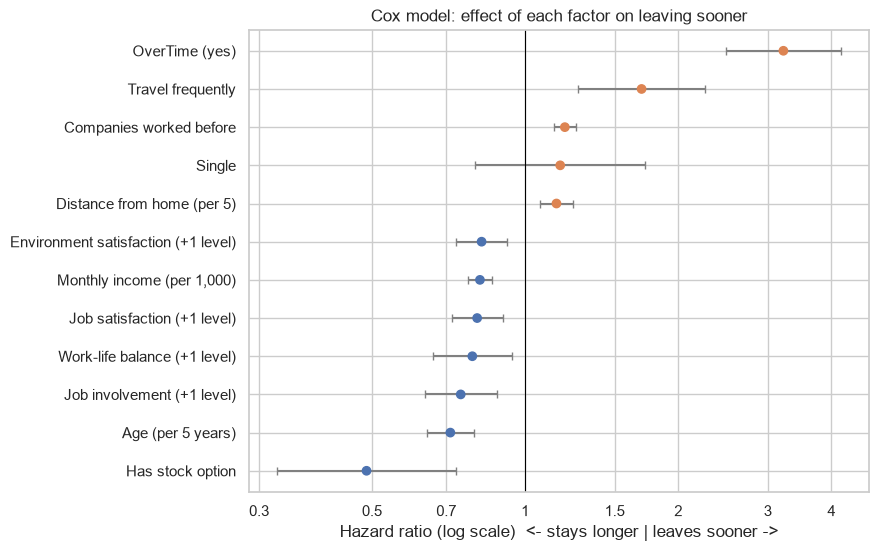

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(hr))
colors = ["#DD8452" if h > 1 else "#4C72B0" for h in hr["HR"]]
ax.errorbar(hr["HR"], y, xerr=[hr["HR"] - hr["HR 95% CI ต่ำ"], hr["HR 95% CI สูง"] - hr["HR"]],
            fmt="none", ecolor="grey", capsize=3)
ax.scatter(hr["HR"], y, color=colors, zorder=3)
ax.axvline(1, color="black", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(hr.index)
ax.set_xscale("log")
ticks = [0.3, 0.5, 0.7, 1, 1.5, 2, 3, 4]
ax.set_xticks(ticks, [str(t) for t in ticks])
ax.minorticks_off()
ax.set_xlabel("Hazard ratio (log scale)  <- stays longer | leaves sooner ->")
ax.set_title("Cox model: effect of each factor on leaving sooner")
save(fig, "04_cox_hazard_ratios")
plt.show()

### ความแม่นของ Cox model (C-index)

C-index = ถ้าสุ่มพนักงาน 2 คนที่คนหนึ่งลาออกก่อน โมเดลให้คะแนนเสี่ยงคนที่ออกก่อนสูงกว่าได้กี่ % (0.5 = เดาสุ่ม, 1.0 = ถูกทุกคู่) อ่านคล้าย AUC ของ classification

ค่านี้วัดบนข้อมูลที่ใช้ fit จึงดูดีกว่าความจริงเล็กน้อย ใช้ดูว่าโมเดลจับทิศทางได้ ไม่ใช่ตัวเลขสำหรับเทียบกับ XGBoost

In [7]:
def c_index(time, event, risk):
    """Harrell's C: คู่ที่เปรียบเทียบได้ = คนที่ลาออก (event) ก่อนอีกคน"""
    t, e, r = np.asarray(time), np.asarray(event), np.asarray(risk)
    comparable = (t[:, None] < t[None, :]) & (e[:, None] == 1)
    concordant = (r[:, None] > r[None, :]) & comparable
    ties = (r[:, None] == r[None, :]) & comparable
    return (concordant.sum() + 0.5 * ties.sum()) / comparable.sum()


risk = cox.to_numpy() @ cox_res.params
print(f"C-index ของ Cox model: {c_index(df['duration'], df['event'], risk):.3f}")

C-index ของ Cox model: 0.866


### ตรวจสมมติฐาน proportional hazards

Cox model สมมติว่าผลของแต่ละปัจจัย "คงที่ตลอดเวลา" (เช่น OT ทำให้เสี่ยง 2 เท่าทั้งปีแรกและปีที่ 10) ตรวจด้วย Schoenfeld residuals: ถ้า residual ของปัจจัยไหนสัมพันธ์กับเวลา (p < 0.05) แปลว่าผลของปัจจัยนั้นเปลี่ยนไปตามเวลา HR ของตัวนั้นเป็น "ค่าเฉลี่ยตลอดช่วง" ต้องตีความอย่างระวัง

In [8]:
from scipy import stats

resid = cox_res.schoenfeld_residuals
has_event = ~np.isnan(resid[:, 0])
ph = []
for j, name in enumerate(cox.columns):
    rho, p = stats.spearmanr(df["duration"].to_numpy()[has_event], resid[has_event, j])
    ph.append({"ปัจจัย": name, "rho กับเวลา": rho, "p_value": p, "ผ่านสมมติฐาน": "ผ่าน" if p >= 0.05 else "ระวัง"})
pd.DataFrame(ph).style.format({"rho กับเวลา": "{:+.3f}", "p_value": "{:.3f}"}).hide(axis="index")

ปัจจัย,rho กับเวลา,p_value,ผ่านสมมติฐาน
OverTime (yes),+0.174,0.007,ระวัง
"Monthly income (per 1,000)",+0.190,0.003,ระวัง
Has stock option,-0.357,0.000,ระวัง
Age (per 5 years),+0.135,0.038,ระวัง
Distance from home (per 5),+0.011,0.860,ผ่าน
Environment satisfaction (+1 level),+0.076,0.243,ผ่าน
Job satisfaction (+1 level),+0.235,0.000,ระวัง
Job involvement (+1 level),-0.034,0.597,ผ่าน
Work-life balance (+1 level),-0.060,0.359,ผ่าน
Travel frequently,-0.367,0.000,ระวัง


---
## ขั้นตอนที่ 6: สรุปผล

ตัวเลขมาจากข้อมูลดิบ 1,470 คน (ลาออก 237 คน)

**1. ช่วงเสี่ยงที่สุดคือ 2 ปีแรก**
- ในคนที่ลาออก **43% ออกภายใน 2 ปีแรก** (YearsAtCompany 0–2)
- ปีที่ 1 (อยู่ครบ 1 ปีแต่ยังไม่ถึง 2) มีอัตราลาออก **4.1%** สูงสุดในช่วง 10 ปีแรก ปีอื่นส่วนใหญ่อยู่ราว 1–2%
- ภาพรวมทั้งบริษัท: ครบ 2 ปียังอยู่ 92.8%, ครบ 5 ปี 87.3%, ครบ 10 ปี 77.7%
- ปีที่ 10 มีอัตราพุ่งเป็น 4.9% (18 จาก 366 คน) อาจเป็นจังหวะ "ครบ 10 ปีแล้วเปลี่ยนงาน" หรือเป็นลักษณะของข้อมูลจำลอง จำนวนคนน้อย ยังสรุปไม่ได้

**2. กลุ่มที่ลาออกเร็วกว่าชัดเจน** (log-rank p < 0.001 ทุกกลุ่ม) ดูจากสัดส่วนที่ยังอยู่เมื่อครบ 5 ปี S(5):
- ระดับตำแหน่ง 1: 71.7% เทียบกับระดับ 2 ขึ้นไป 94.9%
- อายุ 18–29: 73.8% เทียบกับอายุ 40–49: 94.3%
- ทำ OT: 75.9% เทียบกับไม่ทำ 92.0%
- โสด: 78.6% และไม่มี stock option: 80.1% (ดูข้อ 4)
- เดินทางบ่อย: 81.4% เทียบกับไม่ต้องเดินทาง 92.1%

**3. เมื่อดูหลายปัจจัยพร้อมกัน (Cox model, C-index 0.87 วัดบนข้อมูลที่ fit)**
- ทำให้ลาออก**เร็วขึ้น**: ทำ OT **3.2 เท่า** (แรงที่สุด), เดินทางบ่อย 1.7 เท่า, เคยทำงานมาแล้วเพิ่มทุก 1 บริษัท 1.2 เท่า, บ้านไกลขึ้นทุก 5 กม. 1.15 เท่า
- ทำให้อยู่**นานขึ้น**: มี stock option เหลือ 0.49 เท่า (ครึ่งเดียว), อายุมากขึ้นทุก 5 ปี 0.71 เท่า, เงินเดือนมากขึ้นทุก 1,000 0.82 เท่า, ความพึงพอใจ ความทุ่มเท และสมดุลงานกับชีวิตดีขึ้นทุก 1 ระดับ 0.75–0.82 เท่า

**4. "โสด" ไม่มีผลเมื่อคุมปัจจัยอื่นแล้ว (HR 1.17, p = 0.42)** เพราะใน IBM dataset **คนโสดทั้ง 470 คนไม่มี stock option เลย** ผลของสองเรื่องนี้จึงแยกกันไม่ได้ เป็นลักษณะของข้อมูลจำลอง ข้อมูลบริษัทจริงอาจไม่เป็นแบบนี้ (เกี่ยวกับ Fairness check ด้วย เพราะสถานภาพสมรสเป็น protected attribute)

**5. สมมติฐาน proportional hazards ไม่ผ่าน 8 จาก 12 ปัจจัย** แปลว่าผลของปัจจัยเหล่านั้นเปลี่ยนไปตามเวลา เช่น การเดินทางบ่อยมีผลมากในช่วงแรกแล้วลดลง ค่า HR ในข้อ 3 จึงเป็น "ผลเฉลี่ยตลอดช่วง" ทิศทาง (เร็วขึ้น/ช้าลง) ยังใช้ได้ แต่ตัวเลขเท่าไหร่ไม่ควรอ้างแบบเจาะจง ถ้าจะทำต่อ: แยก model ตามช่วงเวลา (stratify) หรือใส่ปัจจัย × เวลา

### นำไปใช้กับ HR ได้ยังไง
- เน้นมาตรการรักษาคนช่วง **2 ปีแรก** (onboarding, mentor, ทบทวนเงินเดือนหลังผ่านโปร) โดยเฉพาะพนักงานระดับ 1 อายุน้อย และคนที่ทำ OT ประจำ
- OT เป็นปัจจัยที่บริษัทควบคุมได้และมีผลแรงที่สุด สอดคล้องกับ SHAP ของโมเดลหลัก
- stock option ในบริบทไทยเทียบได้กับกองทุนสำรองเลี้ยงชีพ (ตาม Localization Notes ใน README)

### ข้อจำกัด
- ข้อมูลเป็น snapshot ไม่มีวันที่ (DS-01) ปัจจัยอย่างเงินเดือนและความพึงพอใจเป็นค่า ณ วันที่ออกหรือวันเก็บข้อมูล ไม่ใช่ค่าตอนเริ่มงาน ผลจึงเป็นความสัมพันธ์ ไม่ใช่เหตุและผล
- IBM dataset เป็นข้อมูลจำลอง ไม่ใช่บริษัทไทยจริง
- C-index วัดบนข้อมูลชุดเดียวกับที่ fit จึงสูงกว่าความจริงเล็กน้อย